# Case Method Data Mining: Analisis Keranjang Belanja Toko Online dengan FP-Growth

**NIM:** L0124132 | **Metode:** Aturan Asosiasi (FP-Growth) | **Dataset:** Online Retail (UCI Machine Learning Repository)


In [2]:
import inspect
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
from collections import Counter
from mlxtend.frequent_patterns import fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

try:
    from google.colab import files
    uploaded = files.upload()
    NAMA_FILE = list(uploaded.keys())[0]
except ImportError:
    NAMA_FILE = "Online_Retail.csv"
print("Berkas:", NAMA_FILE)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Saving Online Retail.csv to Online Retail.csv
Berkas: Online Retail.csv


## Langkah 1: Memahami karakteristik dataset
Setiap baris adalah satu produk pada (`InvoiceNo`). Satu faktur dianggap satu keranjang belanja (transaksi).

In [5]:
df = pd.read_csv(NAMA_FILE, sep=';', decimal=',')

kolom_wajib = {"InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice", "Country"}
kolom_hilang = kolom_wajib - set(df.columns)
if kolom_hilang:
    raise ValueError(f"Kolom dataset tidak lengkap: {sorted(kolom_hilang)}")

print("Ukuran dataset (baris, kolom):", df.shape)
print("Jumlah invoice unik          :", df["InvoiceNo"].nunique())
print("Periode transaksi            :", df["InvoiceDate"].min(), "s.d.", df["InvoiceDate"].max())
print("Jumlah negara                :", df["Country"].nunique())
display(df.head())
display(df.dtypes.rename("Tipe Data").to_frame())

Ukuran dataset (baris, kolom): (541909, 8)
Jumlah invoice unik          : 25900
Periode transaksi            : 01/02/2011 08:23 s.d. 31/10/2011 17:19
Jumlah negara                : 38


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01/12/2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01/12/2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01/12/2010 08:26,3.39,17850.0,United Kingdom


,Tipe Data
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,object
UnitPrice,float64
CustomerID,float64
Country,object


In [6]:
print("Missing value per kolom:")
display(df.isna().sum().rename("Jumlah Missing").to_frame())
print("Baris Quantity <= 0:", (pd.to_numeric(df["Quantity"], errors="coerce") <= 0).sum())
print("Invoice pembatalan (diawali C):", df["InvoiceNo"].astype(str).str.strip().str.startswith("C").sum())
print("\nLima negara dengan transaksi terbanyak:")
display(df["Country"].value_counts().head(5).rename("Jumlah Baris").to_frame())

Missing value per kolom:


,Jumlah Missing
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


Baris Quantity <= 0: 10624
Invoice pembatalan (diawali C): 9288

Lima negara dengan transaksi terbanyak:


,Jumlah Baris
Country,
United Kingdom,495478
Germany,9495
France,8557
EIRE,8196
Spain,2533


## Langkah 2: Preprocessing data
Membersihkan data agar siap dijadikan transaksi: membuang baris tidak valid, pembatalan, kode non-produk, memfokuskan pada satu negara, menghapus item dobel, dan membuang transaksi yang hanya berisi 1 item.

In [7]:
NEGARA = "United Kingdom"
log = []

def catat(tahap, data):
    log.append({
        "Tahap": tahap,
        "Jumlah Baris": len(data),
        "Jumlah Invoice": data["InvoiceNo"].nunique() if "InvoiceNo" in data.columns else 0
    })

# Salin data agar dataset asli tetap utuh
d = df.copy()
catat("Data mentah", d)

# Hapus data yang tidak memiliki identitas transaksi atau nama produk
d = d.dropna(subset=["InvoiceNo", "Description"]).copy()
catat("Hapus InvoiceNo / Description kosong", d)

# Normalisasi invoice dan hilangkan transaksi pembatalan
d["InvoiceNo"] = d["InvoiceNo"].astype(str).str.strip()
d = d[~d["InvoiceNo"].str.upper().str.startswith("C")].copy()
catat("Hapus invoice pembatalan", d)

# Pastikan quantity numerik dan positif
d["Quantity"] = pd.to_numeric(d["Quantity"], errors="coerce")
d = d[d["Quantity"] > 0].copy()
catat("Hapus Quantity tidak valid / <= 0", d)

# Hapus kode non-produk (ongkir, biaya admin, dll.): kode produk valid diawali 5 digit angka
d = d[d["StockCode"].astype(str).str.match(r"^\d{5}")].copy()
catat("Hapus kode non-produk", d)

# Bersihkan deskripsi dan pilih negara
d["Description"] = d["Description"].astype(str).str.strip().str.upper()
d = d[d["Description"].ne("")].copy()
d["Country"] = d["Country"].astype(str).str.strip()
d = d[d["Country"].str.casefold() == NEGARA.casefold()].copy()
catat(f"Filter negara: {NEGARA}", d)

# Satu produk cukup dihitung sekali dalam satu invoice
d = d.drop_duplicates(subset=["InvoiceNo", "Description"])
catat("Hapus duplikasi produk per invoice", d)

# Pertahankan transaksi dengan minimal dua produk unik
jumlah_item = d.groupby("InvoiceNo")["Description"].nunique()
invoice_multi_item = jumlah_item[jumlah_item >= 2].index
d = d[d["InvoiceNo"].isin(invoice_multi_item)].copy()
catat("Hapus transaksi dengan kurang dari 2 produk", d)

ringkasan_preprocessing = pd.DataFrame(log)
display(ringkasan_preprocessing)

if d.empty:
    raise ValueError("Tidak ada data tersisa setelah preprocessing. Periksa filter dan dataset.")

jumlah_transaksi = d["InvoiceNo"].nunique()
jumlah_produk = d["Description"].nunique()
rata_item = d.groupby("InvoiceNo")["Description"].nunique().mean()
print(f"\nTransaksi akhir       : {jumlah_transaksi:,}")
print(f"Produk unik           : {jumlah_produk:,}")
print(f"Rata-rata produk/transaksi: {rata_item:.2f}")

,Tahap,Jumlah Baris,Jumlah Invoice
0,Data mentah,541909,25900
1,Hapus InvoiceNo / Description kosong,540455,24446
2,Hapus invoice pembatalan,531167,20610
3,Hapus Quantity tidak valid / <= 0,530693,20136
4,Hapus kode non-produk,528302,19954
5,Filter negara: United Kingdom,484533,18081
6,Hapus duplikasi produk per invoice,473951,18081
7,Hapus transaksi dengan kurang dari 2 produk,472393,16523



Transaksi akhir       : 16,523
Produk unik           : 3,969
Rata-rata produk/transaksi: 28.59


## Langkah 3: Menganalisis pola awal dan membentuk transaksi biner
Sebelum FP-Growth, lihat dulu produk yang paling sering dibeli, lalu ubah data menjadi matriks transaksi biner (baris = faktur, kolom = produk, nilai True jika produk ada di faktur tersebut).

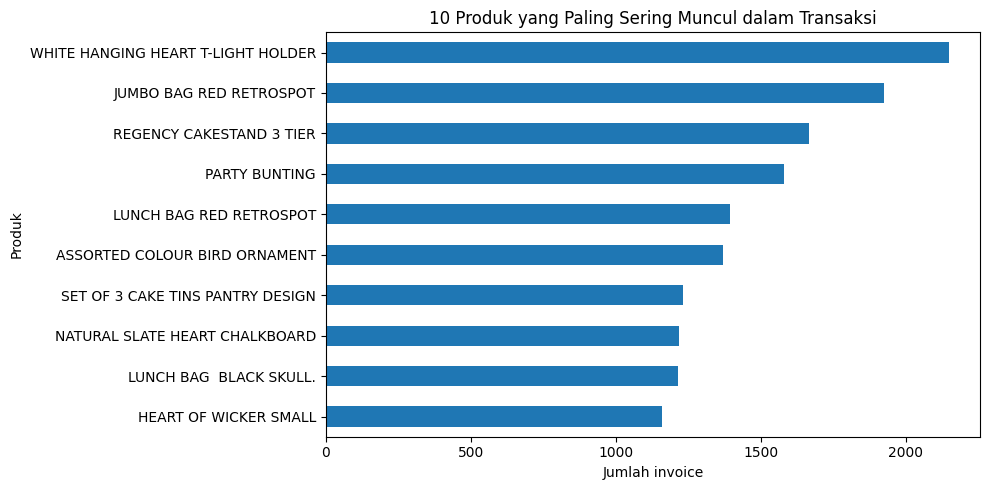

,Jumlah Invoice
Description,
WHITE HANGING HEART T-LIGHT HOLDER,2148
JUMBO BAG RED RETROSPOT,1923
REGENCY CAKESTAND 3 TIER,1665
PARTY BUNTING,1579
LUNCH BAG RED RETROSPOT,1392
ASSORTED COLOUR BIRD ORNAMENT,1369
SET OF 3 CAKE TINS PANTRY DESIGN,1233
NATURAL SLATE HEART CHALKBOARD,1218
LUNCH BAG BLACK SKULL.,1214


Contoh 3 transaksi:
Transaksi 1: ['CREAM CUPID HEARTS COAT HANGER', 'GLASS STAR FROSTED T-LIGHT HOLDER', 'KNITTED UNION FLAG HOT WATER BOTTLE', 'RED WOOLLY HOTTIE WHITE HEART.', 'SET 7 BABUSHKA NESTING BOXES', 'WHITE HANGING HEART T-LIGHT HOLDER', 'WHITE METAL LANTERN']
Transaksi 2: ['HAND WARMER RED POLKA DOT', 'HAND WARMER UNION JACK']
Transaksi 3: ['ASSORTED COLOUR BIRD ORNAMENT', 'BOX OF 6 ASSORTED COLOUR TEASPOONS', 'BOX OF VINTAGE ALPHABET BLOCKS', 'BOX OF VINTAGE JIGSAW BLOCKS', 'DOORMAT NEW ENGLAND', 'FELTCRAFT PRINCESS CHARLOTTE DOLL', 'HOME BUILDING BLOCK WORD', 'IVORY KNITTED MUG COSY', 'LOVE BUILDING BLOCK WORD', "POPPY'S PLAYHOUSE BEDROOM", "POPPY'S PLAYHOUSE KITCHEN", 'RECIPE BOX WITH METAL HEART']
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [8]:
top_produk = (d.groupby("Description")["InvoiceNo"].nunique()
              .sort_values(ascending=False).head(10))

top_produk.sort_values().plot.barh(figsize=(10, 5), title="10 Produk yang Paling Sering Muncul dalam Transaksi")
plt.xlabel("Jumlah invoice")
plt.ylabel("Produk")
plt.tight_layout()
plt.show()
display(top_produk.rename("Jumlah Invoice").to_frame())

# Satu list produk unik untuk setiap invoice
transactions = (d.groupby("InvoiceNo")["Description"]
                .apply(lambda x: sorted(set(x)))
                .tolist())
print("Contoh 3 transaksi:")
for i, basket in enumerate(transactions[:3], start=1):
    print(f"Transaksi {i}: {basket[:12]}")

In [9]:
te = TransactionEncoder()
matriks_sparse = te.fit(transactions).transform(transactions, sparse=True)
onehot = pd.DataFrame.sparse.from_spmatrix(matriks_sparse, columns=te.columns_)

print("Ukuran matriks transaksi:", onehot.shape)
print("Tipe penyimpanan kolom:", onehot.dtypes.iloc[0] if onehot.shape[1] else "Tidak ada kolom")
display(onehot.iloc[:5, :10])

Ukuran matriks transaksi: (16523, 3969)
Tipe penyimpanan kolom: Sparse[bool, 0]


/tmp/ipykernel_2678/804864474.py:3: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  onehot = pd.DataFrame.sparse.from_spmatrix(matriks_sparse, columns=te.columns_)
/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:93: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  nunique = column.nunique()
/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:99: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  non_null_values = column[column.notnull()].unique()
/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:103: FutureWarning: Allowing arbitrary scalar fill

,*BOOMBOX IPOD CLASSIC,*USB OFFICE MIRROR BALL,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND
0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0


## Langkah 4: Menggunakan algoritma FP-Growth
Parameter dapat diubah. Turunkan `MIN_SUPPORT` (mis. 0.01) jika ingin pola yang lebih banyak.

In [10]:
MIN_SUPPORT = 0.02
MIN_CONFIDENCE = 0.50
MIN_LIFT = 1.00
MAX_LEN = 3

if not (0 < MIN_SUPPORT <= 1):
    raise ValueError("MIN_SUPPORT harus berada pada rentang (0, 1].")

freq = fpgrowth(
    onehot,
    min_support=MIN_SUPPORT,
    use_colnames=True,
    max_len=MAX_LEN
)

if freq.empty:
    raise ValueError(
        "Tidak ditemukan frequent itemset. Coba turunkan MIN_SUPPORT, misalnya menjadi 0.01."
    )

freq["panjang"] = freq["itemsets"].apply(len)
print("Jumlah frequent itemsets:", len(freq))
display(freq["panjang"].value_counts().sort_index().rename("Jumlah Itemsets").to_frame())
display(freq.sort_values("support", ascending=False).head(15))

Jumlah frequent itemsets: 475


,Jumlah Itemsets
panjang,
1,349
2,120
3,6


,support,itemsets,panjang
0,0.130001,(WHITE HANGING HEART T-LIGHT HOLDER),1
63,0.116383,(JUMBO BAG RED RETROSPOT),1
174,0.100769,(REGENCY CAKESTAND 3 TIER),1
279,0.095564,(PARTY BUNTING),1
19,0.084246,(LUNCH BAG RED RETROSPOT),1
5,0.082854,(ASSORTED COLOUR BIRD ORNAMENT),1
291,0.074623,(SET OF 3 CAKE TINS PANTRY DESIGN),1
50,0.073715,(NATURAL SLATE HEART CHALKBOARD),1
108,0.073473,(LUNCH BAG BLACK SKULL.),1
51,0.070205,(HEART OF WICKER SMALL),1


## Langkah 5: Mengevaluasi hasil (support, confidence, lift)
Aturan dianggap bermakna jika lift lebih dari 1 (kedua produk muncul bersamaan lebih sering daripada kebetulan).

In [11]:
parameter_rules = inspect.signature(association_rules).parameters
kwargs_rules = {"metric": "confidence", "min_threshold": MIN_CONFIDENCE}
if "num_itemsets" in parameter_rules:
    kwargs_rules["num_itemsets"] = len(onehot)

# association_rules membutuhkan frequent itemset berukuran minimal 2
freq_rules_input = freq[freq["itemsets"].apply(len) >= 2].copy()

if freq_rules_input.empty:
    hasil = pd.DataFrame(columns=["antecedents", "consequents", "support", "confidence", "lift", "items"])
    print("Belum ada frequent itemset berukuran 2; tidak dapat membentuk association rules.")
else:
    rules = association_rules(freq, **kwargs_rules)
    rules = rules[rules["lift"] > MIN_LIFT].copy()
    rules["items"] = rules.apply(lambda r: r["antecedents"] | r["consequents"], axis=1)
    hasil = rules[["antecedents", "consequents", "support", "confidence", "lift", "items"]].copy()
    hasil["antecedents"] = hasil["antecedents"].apply(lambda s: " + ".join(sorted(s)))
    hasil["consequents"] = hasil["consequents"].apply(lambda s: " + ".join(sorted(s)))
    hasil = hasil.sort_values(["lift", "confidence", "support"], ascending=False).reset_index(drop=True)

print("Jumlah aturan asosiasi yang memenuhi kriteria:", len(hasil))
if not hasil.empty:
    display(hasil.drop(columns="items").head(15).round(4))
else:
    print("Tidak ada aturan yang memenuhi kriteria. Pertimbangkan menurunkan MIN_SUPPORT atau MIN_CONFIDENCE.")

Jumlah aturan asosiasi yang memenuhi kriteria: 95


,antecedents,consequents,support,confidence,lift
0,SMALL MARSHMALLOWS PINK BOWL,SMALL DOLLY MIX DESIGN ORANGE BOWL,0.0203,0.7791,25.2403
1,SMALL DOLLY MIX DESIGN ORANGE BOWL,SMALL MARSHMALLOWS PINK BOWL,0.0203,0.6569,25.2403
2,WOODEN STAR CHRISTMAS SCANDINAVIAN,WOODEN HEART CHRISTMAS SCANDINAVIAN,0.0223,0.7699,24.9914
3,WOODEN HEART CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,0.0223,0.7230,24.9914
4,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER + ROSES REGENC...,0.0298,0.7053,16.6242
5,GREEN REGENCY TEACUP AND SAUCER + ROSES REGENC...,PINK REGENCY TEACUP AND SAUCER,0.0298,0.7033,16.6242
6,HAND WARMER OWL DESIGN,HAND WARMER SCOTTY DOG DESIGN,0.0200,0.5271,16.2781
7,HAND WARMER SCOTTY DOG DESIGN,HAND WARMER OWL DESIGN,0.0200,0.6187,16.2781
8,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY...,GREEN REGENCY TEACUP AND SAUCER,0.0298,0.9029,15.9734
9,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY...,0.0298,0.5278,15.9734


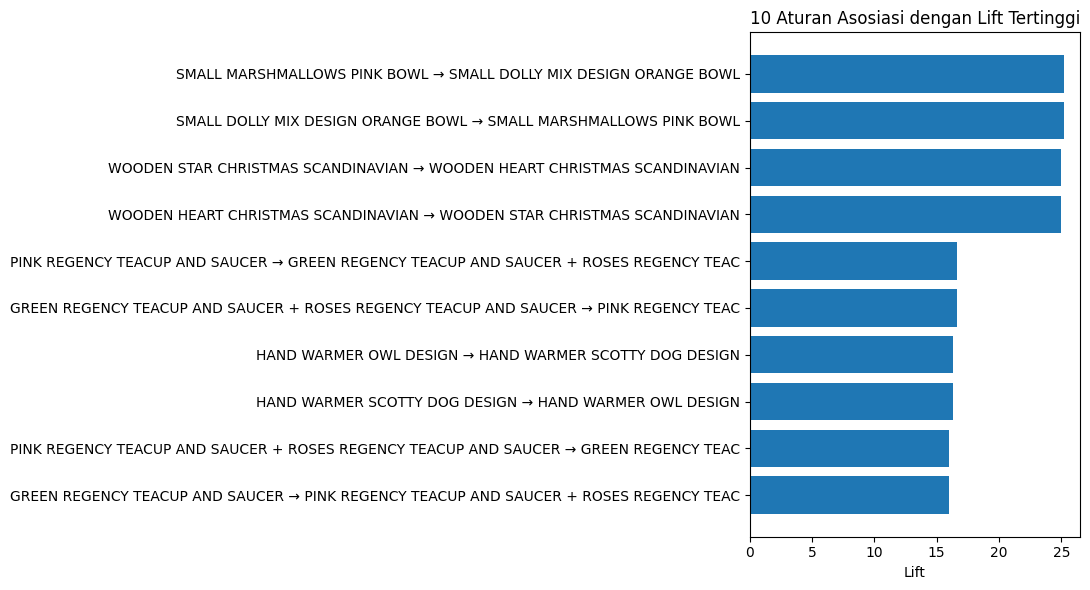

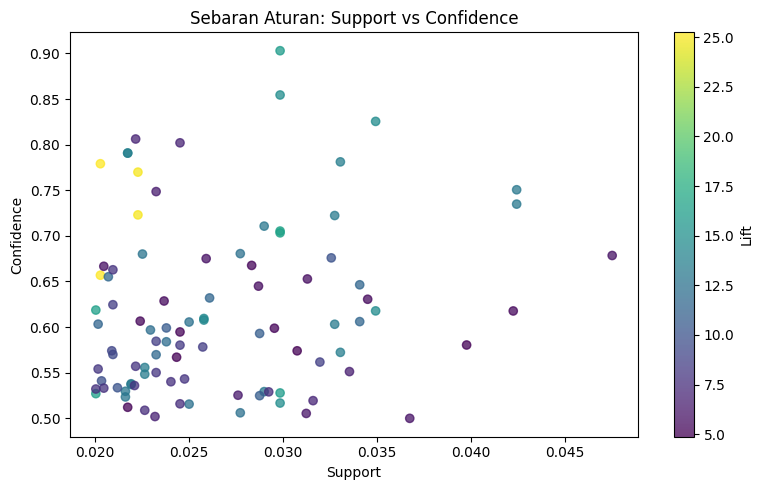

In [12]:
if not hasil.empty:
    top = hasil.head(10).iloc[::-1]
    label = (top["antecedents"] + " → " + top["consequents"]).str.slice(0, 85)
    plt.figure(figsize=(11, 6))
    plt.barh(label, top["lift"])
    plt.xlabel("Lift")
    plt.title("10 Aturan Asosiasi dengan Lift Tertinggi")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 5))
    sc = plt.scatter(hasil["support"], hasil["confidence"], c=hasil["lift"], cmap="viridis", alpha=0.75)
    plt.colorbar(sc, label="Lift")
    plt.xlabel("Support")
    plt.ylabel("Confidence")
    plt.title("Sebaran Aturan: Support vs Confidence")
    plt.tight_layout()
    plt.show()
else:
    print("Visualisasi aturan dilewati karena belum ada association rules.")

## Langkah 6: Menentukan pola / faktor paling berpengaruh
Produk yang paling sering muncul pada 20 aturan dengan lift tertinggi dianggap paling berpengaruh dalam pola pembelian bersamaan.

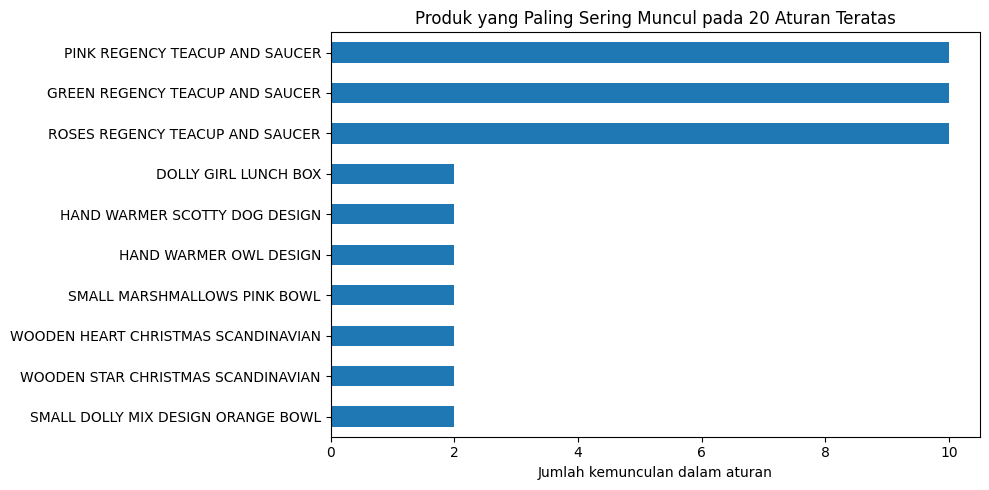

,Jumlah Kemunculan
PINK REGENCY TEACUP AND SAUCER,10
GREEN REGENCY TEACUP AND SAUCER,10
ROSES REGENCY TEACUP AND SAUCER,10
SMALL DOLLY MIX DESIGN ORANGE BOWL,2
SMALL MARSHMALLOWS PINK BOWL,2
WOODEN HEART CHRISTMAS SCANDINAVIAN,2
WOODEN STAR CHRISTMAS SCANDINAVIAN,2
HAND WARMER OWL DESIGN,2
HAND WARMER SCOTTY DOG DESIGN,2
DOLLY GIRL LUNCH BOX,2


In [13]:
if not hasil.empty:
    cnt = Counter()
    for itemset in hasil.head(20)["items"]:
        cnt.update(itemset)

    pengaruh = pd.Series(dict(cnt.most_common(10)), dtype="int64")
    if not pengaruh.empty:
        pengaruh.sort_values().plot.barh(figsize=(10, 5), title="Produk yang Paling Sering Muncul pada 20 Aturan Teratas")
        plt.xlabel("Jumlah kemunculan dalam aturan")
        plt.tight_layout()
        plt.show()
        display(pengaruh.sort_values(ascending=False).rename("Jumlah Kemunculan").to_frame())
else:
    pengaruh = pd.Series(dtype="int64")
    print("Analisis produk berpengaruh dilewati karena tidak ada aturan asosiasi.")

## Langkah 7: Rekomendasi kepada manajemen
Berdasarkan pola yang ditemukan (produk dalam satu seri/koleksi cenderung dibeli bersamaan):

1. **Bundling set produk**, misalnya set cangkir Regency lengkap dan dekorasi Natal bertema Scandinavian.
2. **Fitur "sering dibeli bersama"** pada halaman produk berdasarkan aturan dengan lift dan confidence tinggi.
3. **Rekomendasi di keranjang**: jika pelanggan menambah dua varian satu seri, tawarkan varian ketiga.
4. **Promosi musiman** untuk paket produk bertema Natal menjelang akhir tahun.
5. **Perencanaan stok**: jaga ketersediaan semua varian dalam satu seri.

In [14]:
if not hasil.empty:
    print("REKOMENDASI BERDASARKAN HASIL DATA")
    for nomor, (_, row) in enumerate(hasil.head(5).iterrows(), start=1):
        print(
            f"{nomor}. Ketika pelanggan membeli [{row['antecedents']}], "
            f"produk [{row['consequents']}] dapat dipertimbangkan untuk direkomendasikan "
            f"(support={row['support']:.3f}, confidence={row['confidence']:.3f}, lift={row['lift']:.3f})."
        )
    print("\nTindak lanjut yang dapat dipertimbangkan:")
    print("- Uji penempatan rekomendasi 'sering dibeli bersama' untuk pasangan produk dengan confidence dan lift tinggi.")
    print("- Evaluasi bundling/promosi sebagai eksperimen; aturan asosiasi sendiri tidak membuktikan peningkatan penjualan.")
    print("- Periksa ketersediaan stok produk yang sering muncul bersama sebelum menjalankan promosi.")
else:
    print("Belum ada aturan untuk dijadikan dasar rekomendasi spesifik. Sesuaikan parameter dan jalankan ulang.")

REKOMENDASI BERDASARKAN HASIL DATA
1. Ketika pelanggan membeli [SMALL MARSHMALLOWS PINK BOWL], produk [SMALL DOLLY MIX DESIGN ORANGE BOWL] dapat dipertimbangkan untuk direkomendasikan (support=0.020, confidence=0.779, lift=25.240).
2. Ketika pelanggan membeli [SMALL DOLLY MIX DESIGN ORANGE BOWL], produk [SMALL MARSHMALLOWS PINK BOWL] dapat dipertimbangkan untuk direkomendasikan (support=0.020, confidence=0.657, lift=25.240).
3. Ketika pelanggan membeli [WOODEN STAR CHRISTMAS SCANDINAVIAN], produk [WOODEN HEART CHRISTMAS SCANDINAVIAN] dapat dipertimbangkan untuk direkomendasikan (support=0.022, confidence=0.770, lift=24.991).
4. Ketika pelanggan membeli [WOODEN HEART CHRISTMAS SCANDINAVIAN], produk [WOODEN STAR CHRISTMAS SCANDINAVIAN] dapat dipertimbangkan untuk direkomendasikan (support=0.022, confidence=0.723, lift=24.991).
5. Ketika pelanggan membeli [PINK REGENCY TEACUP AND SAUCER], produk [GREEN REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER] dapat dipertimbangkan untu